In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import pendulum as pdl
import datetime as dt

In [2]:

# Create a dataframe which defines the 
loadcase_timesheet = pd.DataFrame(columns=["LC","lc-title","timestamp"])
start_date = pd.to_datetime("2023-11-01 00:00:00")

# create the 10 loadsteps for the creep load case
simulation_duration = 365 #days
simulation_steps = 30
for i in range(1,simulation_steps+1):
    loadcase_timesheet.loc[i - 1] = {
        "LC": 40074 + i,
        "lc-title": "Creep until start of load test",
        "timestamp": start_date + i * pdl.Duration(
            days=simulation_duration / simulation_steps
        ),
    }

print(loadcase_timesheet.timestamp.dtype)
loadcase_timesheet.head(11)

datetime64[us]


,LC,lc-title,timestamp
0,40075,Creep until start of load test,2023-11-13 04:00:00
1,40076,Creep until start of load test,2023-11-25 08:00:00
2,40077,Creep until start of load test,2023-12-07 12:00:00
3,40078,Creep until start of load test,2023-12-19 16:00:00
4,40079,Creep until start of load test,2023-12-31 20:00:00
5,40080,Creep until start of load test,2024-01-13 00:00:00
6,40081,Creep until start of load test,2024-01-25 04:00:00
7,40082,Creep until start of load test,2024-02-06 08:00:00
8,40083,Creep until start of load test,2024-02-18 12:00:00
9,40084,Creep until start of load test,2024-03-01 16:00:00


In [ ]:
# the sofistic produces CSV files with:
#  LC, Node, u-X, u-Y, u-Z, r-X, r-Y, r-Z, ...
# loaded_data = pd.read_csv("test-openlab-export.csv",)
loaded_data = pd.read_csv("openlab-sensors-export.csv",)
sensors = pd.read_csv("IFC_Sensor_Coordinates.csv",)
# loaded data format correction|
p = loaded_data.columns
loaded_data[p[3:]] = loaded_data[p[3:]].apply(lambda x: x.str.replace(',', '.'))
loaded_data[p[3:]] = loaded_data[p[3:]].apply(lambda x: pd.to_numeric(x, errors='coerce'))


def from_mrad_to_mm_per_m(mrad):
    """Convert mrad to mm/m"""
    print(mrad.dtype)
    # mrad.str.replace(",", ".", inplace=True)
    values = pd.to_numeric(mrad, errors="raise")
    return np.tan(values * 1e-3) * 1000

for _, sensor in sensors.iterrows():
    # get senor ref name
    refnum = sensor["sofistik_ref_number"]
    if refnum is None:
        continue
    # extract the relevant predictions
    dftemp = loaded_data["NODE "] == refnum
    dftemp = loaded_data[dftemp]
    if dftemp.empty:
        continue
    else:
        dftemp = dftemp.query("`LC-title ` == 'Creep until start of load test'")
        dftemp = dftemp.copy()
        QoI_dict = {
            "Tilt-X": from_mrad_to_mm_per_m(dftemp["phi-Y [mrad]"].values),
            "Tilt-Y": from_mrad_to_mm_per_m(dftemp["phi-X [mrad]"].values),
            "Displacement-X": dftemp["u-X [mm]"].values,
            "Displacement-Y": dftemp["u-Y [mm]"].values,
            "Displacement-Z": dftemp["u-Z [mm]"].values,
        }
        SensorNameDict = {
            "NGS": "TIL",
            "FT": "PE",
            "BU": "CB",
        }
        sensor_name = sensor["Name"]
        for key, value in SensorNameDict.items():
            sensor_name = sensor_name.replace(key, value)
        # create a new column with the sensor name
        try:
            qoi = QoI_dict[sensor["QoI"]]
        except KeyError:
            print(f"QoI {sensor['QoI']} not found for sensor {sensor['Name']}")
            continue
        loadcase_timesheet[sensor_name] = qoi
        
loadcase_timesheet.head(11)


float64
float64
float64
float64
float64
float64
QoI Temperature not found for sensor G_NGST_FT12_BU1100_0
float64
float64
float64
float64


,LC,lc-title,timestamp,G_TILX_PE12_CB1100_0,G_TILY_PE12_CB1100_0,G_TILX_PE13_CB1100_0,G_TILY_PE13_CB1100_0
0,40075,Creep until start of load test,2023-11-13 04:00:00,-0.754,0.021,0.923000,0.014
1,40076,Creep until start of load test,2023-11-25 08:00:00,-0.766,0.022,0.974000,0.014
2,40077,Creep until start of load test,2023-12-07 12:00:00,-0.775,0.022,1.014000,0.014
3,40078,Creep until start of load test,2023-12-19 16:00:00,-0.784,0.022,1.052000,0.014
4,40079,Creep until start of load test,2023-12-31 20:00:00,-0.792,0.023,1.085000,0.014
5,40080,Creep until start of load test,2024-01-13 00:00:00,-0.799,0.023,1.114000,0.014
6,40081,Creep until start of load test,2024-01-25 04:00:00,-0.806,0.023,1.142000,0.014
7,40082,Creep until start of load test,2024-02-06 08:00:00,-0.812,0.023,1.167001,0.014
8,40083,Creep until start of load test,2024-02-18 12:00:00,-0.818,0.024,1.189001,0.014
9,40084,Creep until start of load test,2024-03-01 16:00:00,-0.823,0.024,1.209001,0.014


In [13]:
# prform a join between the two dataframes to map the LC to timestamps 
# loaded_data.join(loadcase_timesheet.set_index("LC"), on=0, how="left", rsuffix="_timestamp")
        
loaded_data[loaded_data["LC-title "]=="Creep until start of load test" ].head()
cpdf = loaded_data[loaded_data["LC-title "]=="Creep until start of load test" ].copy()

cpdf["LC "] = cpdf["LC "].astype(str).str.strip()
loadcase_timesheet["LC"] = loadcase_timesheet["LC"].astype(str).str.strip()

timestamp_map = loadcase_timesheet.set_index("LC")["timestamp"]

print(timestamp_map.dtype)

# cpdf["timestamp"] = cpdf["LC "].map(timestamp_map)
cpdf["timestamp"] = cpdf["LC "].map(loadcase_timesheet.set_index("LC")["timestamp"])
cpdf.head()

datetime64[us]


,LC,LC-title,NODE,u-X [mm],u-Y [mm],u-Z [mm],phi-X [mrad],phi-Y [mrad],phi-Z [mrad],timestamp
0,140075,Creep until start of load test,1140,2.055,0.005,-5.192,0.059,-0.937,0.0,NaT
1,140075,Creep until start of load test,1170,1.119,0.006,-3.557,0.053,-1.441,0.0,NaT
2,140075,Creep until start of load test,1190,-0.545,0.005,0.879,0.023,-2.183,0.0,NaT
3,140075,Creep until start of load test,1200,-1.300,0.005,1.099,0.021,-0.754,0.0,NaT
4,140075,Creep until start of load test,1201,-1.677,-0.006,1.099,0.021,-0.754,0.0,NaT


In [14]:
print(cpdf.columns)
cpdf["timestamp"].head()



Index(['LC ', 'LC-title ', 'NODE ', 'u-X [mm]', 'u-Y [mm]', 'u-Z [mm]',
       'phi-X [mrad]', 'phi-Y [mrad]', 'phi-Z [mrad]', 'timestamp'],
      dtype='str')


0   NaT
1   NaT
2   NaT
3   NaT
4   NaT
Name: timestamp, dtype: datetime64[us]

<Axes: title={'center': 'Displacement over time for Creep Load Case'}, xlabel='Load Case', ylabel='Rotation [mrad*10]'>

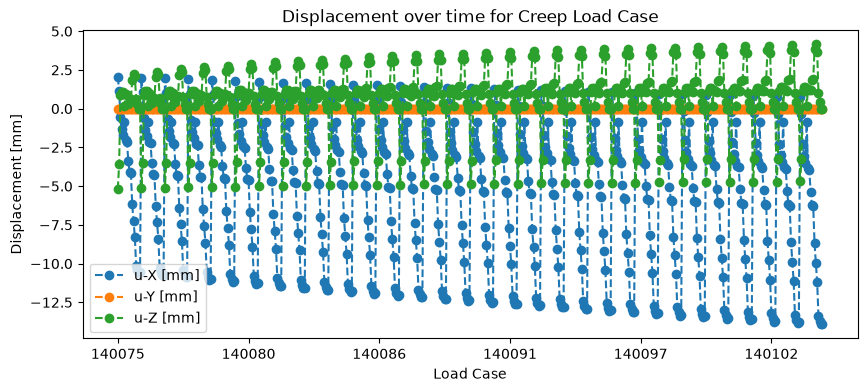

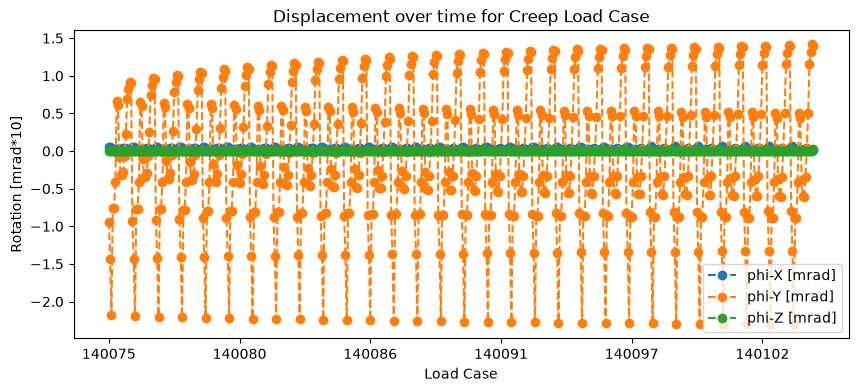

In [15]:
cpdf.plot(x="LC ", y=['u-X [mm]', 'u-Y [mm]', 'u-Z [mm]'],
          title="Displacement over time for Creep Load Case",
          xlabel="Load Case", ylabel="Displacement [mm]", marker='o', linestyle='--', figsize=(10, 4))

rotation_columns = ["phi-X [mrad]", "phi-Y [mrad]", "phi-Z [mrad]"]
# .assign(y_scaled=lambda d: d[rotation_columns[2]] * 10).
cpdf.plot(x="LC ", y=rotation_columns,
          title="Displacement over time for Creep Load Case",
          xlabel="Load Case", ylabel="Rotation [mrad*10]", marker='o', linestyle='--', figsize=(10, 4))

In [ ]:
loadcase_timesheet.plot(x="timestamp", y="",
                        title="Tilt over time for Creep Load Case",
                        xlabel="Timestamp", ylabel="Tilt [mrad]", marker='o', linestyle='--', figsize=(10, 4))  

KeyError: 'tilt_y'

In [12]:
# save the csv dataframe
loadcase_timesheet.to_csv("tiltmeters_prediction.csv", index=False)